**Parte 1**

In [99]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

pi = np.pi

In [100]:
num = 51  ### Número de pontos
if num % 2 == 0: num += 1

theta = np.linspace(0,pi,num)
phi = np.linspace(0,pi,num)

a = 1
b = 0

lamb = 100

k = (2*pi)/lamb

f = lambda rho_s,phi_s : rho_s ** 2 * np.exp(1j*k*rho_s*np.sin(theta)*np.cos(phi-phi_s))

### Intervalo de análise
x1 = 0
x2 = a
y1 = 0
y2 = 2*pi

rho_l = np.linspace(x1,x2,num)
phi_l = np.linspace(y1,y2,num)

# eixos para broadcasting: (phi, rho', phi')
PHI  = phi[:, None, None]
RHO  = rho_l[None, :, None]
PHIL = phi_l[None, None, :]

I = np.zeros((num, num), dtype=complex)   # I[theta, phi]

for i, th in enumerate(theta):
    integrando = RHO**2 * np.exp(1j*k*RHO*np.sin(th)*np.cos(PHI - PHIL))
    # integra em phi' (eixo 2) e depois em rho' (eixo 1)
    I[i, :] = simpson(simpson(integrando, x=phi_l, axis=2), x=rho_l, axis=1)

TH, PH = np.meshgrid(theta, phi, indexing='ij')

E_theta =  np.cos(TH)*np.cos(PH)*I
E_phi   = -np.sin(PH)*I

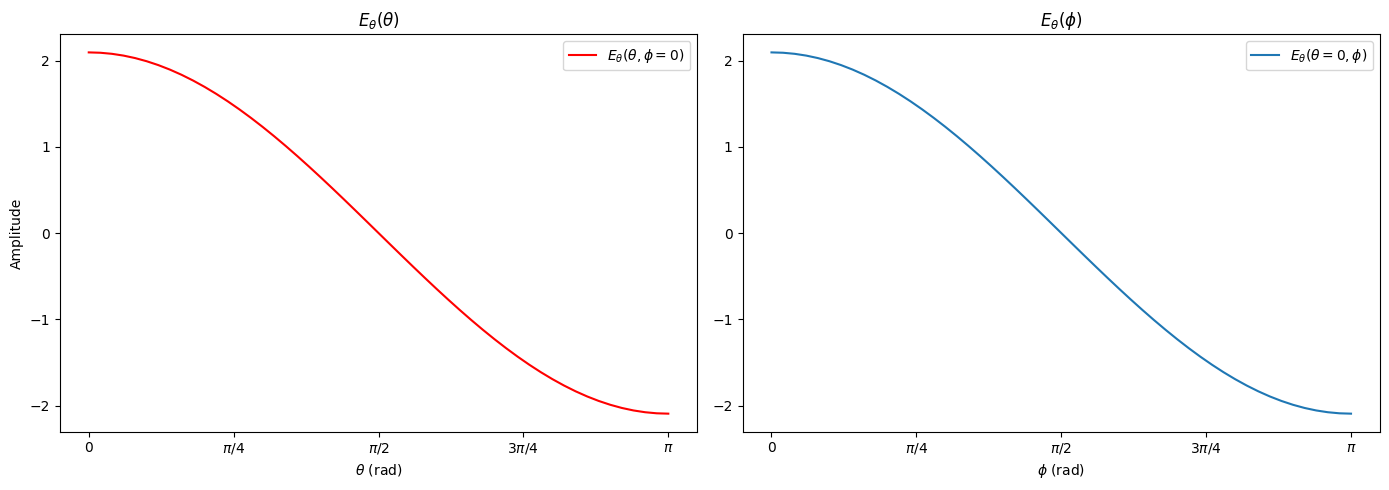

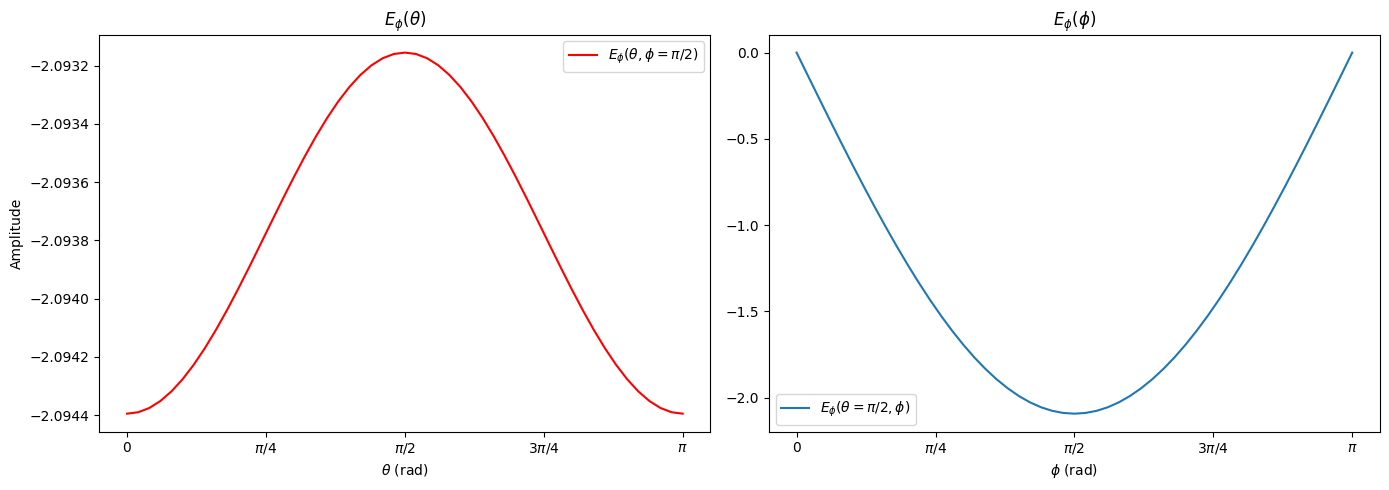

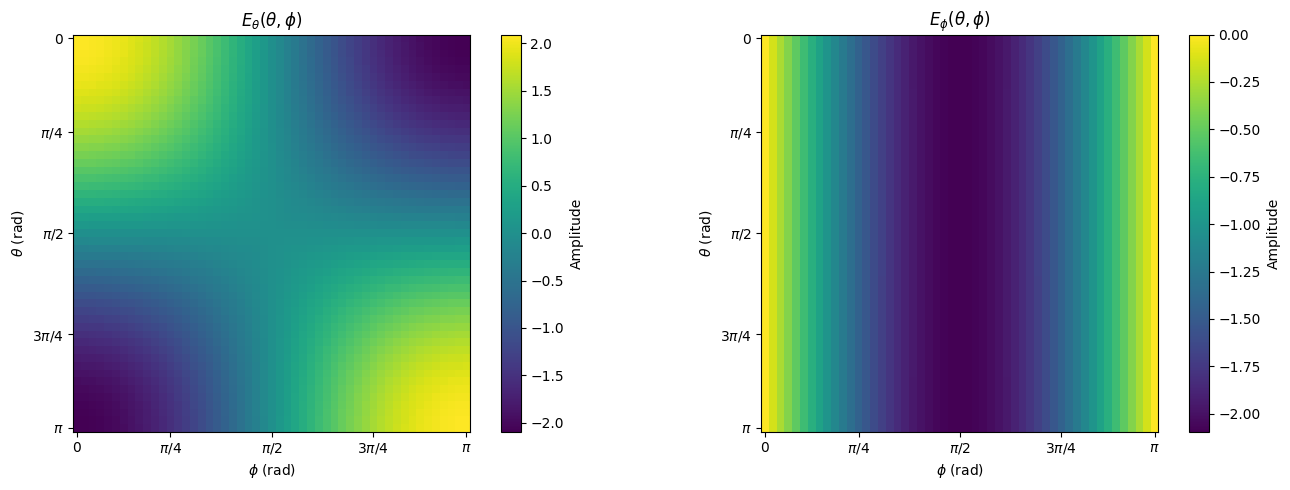

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\phi)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$',color='red')
ax[1].plot(phi,np.real(E_theta[0,:]),label=r'$E_{\theta}(\theta=0,\phi)$')
for i in [0,1]:
    ax[i].set_xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].legend()

ax[0].set_xlabel(r'$\theta$ (rad)')
ax[1].set_xlabel(r'$\phi$ (rad)')
ax[0].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\phi)$')

ax[0].plot(theta,np.real(E_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$',color='red')
ax[1].plot(phi,np.real(E_phi[int(num/2),:]),label=r'$E_{\phi}(\theta=\pi/2,\phi)$')

for i in [0,1]:
    ax[i].set_xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].legend()

ax[0].set_xlabel(r'$\theta$ (rad)')
ax[1].set_xlabel(r'$\phi$ (rad)')
ax[0].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

im0 = ax[0].imshow(np.real(E_theta),cmap='viridis')
ax[0].set_title(r'$E_\theta(\theta,\phi)$')
fig.colorbar(im0, ax=ax[0], label='Amplitude')

im1 = ax[1].imshow(np.real(E_phi),cmap='viridis')
ax[1].set_title(r'$E_\phi(\theta,\phi)$')
fig.colorbar(im1, ax=ax[1], label='Amplitude')

for i in [0,1]:
    ax[i].set_ylabel(r'$\theta$ (rad)')
    ax[i].set_xlabel(r'$\phi$ (rad)')
    ax[i].set_xticks([ 0, int(num/4), int(num/2),int(3*num/4), num-1],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])
    ax[i].set_yticks([ 0, int(num/4), int(num/2),int(3*num/4), num-1],[r"$0$", r"$\pi/4$", r"$\pi/2$",r"$3\pi/4$",r"$\pi$"])

plt.tight_layout()
plt.show()